## Helper Functions

### Helper function to visualize the images with their respective RGB 3D distribution


In [24]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objs as go

def visualize_images_and_distributions(source, target, result, subsample_factor=10, interactive_plot=False):
    """
    Display source, target, and result images (top row)
    and their RGB color distributions (bottom row).

    Parameters
    ----------
    source, target, result : np.ndarray
        Input images in RGB format (values in [0, 1] or [0, 255]).
    subsample_factor : int, optional
        Factor by which to subsample pixels for faster visualization (default=10).
    interactive_plot : bool, optional
        If True, shows Plotly 3D interactive color distributions (separate windows).
        If False, shows them in static Matplotlib 3D plots.
    """

    def preprocess_image(img):
        """Ensure image is float in [0,1] and flattened."""
        if img.dtype == np.uint8:
            img = img / 255.0
        X = img.reshape((-1, 3))
        if subsample_factor > 1:
            nb = int(X.shape[0] / subsample_factor)
            r = np.random.RandomState(42)
            idx = r.randint(X.shape[0], size=(nb,))
            X = X[idx, :]
        return X

    # Prepare data
    imgs = {
        "Source": (source, preprocess_image(source)),
        "Target": (target, preprocess_image(target)),
        "Result": (result, preprocess_image(result))
    }

    # === Create a 2x3 Matplotlib figure ===
    fig = plt.figure(figsize=(15, 10), constrained_layout=True)

    # --- Top row: original images ---
    for i, (title, (img, _)) in enumerate(imgs.items(), start=1):
        ax = fig.add_subplot(2, 3, i)
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    # --- Bottom row: 3D RGB distributions ---
    for i, (title, (_, Xs)) in enumerate(imgs.items(), start=1):
        ax = fig.add_subplot(2, 3, i + 3, projection='3d')
        ax.scatter(Xs[:, 0], Xs[:, 1], Xs[:, 2], c=Xs, s=8)
        ax.set_xlabel("R")
        ax.set_ylabel("G")
        ax.set_zlabel("B")
        ax.set_title(f"{title} RGB Distribution")
        ax.view_init(elev=20, azim=135)

    fig.suptitle("Image Comparison and 3D RGB Distributions", fontsize=15, y=0.98)
    plt.tight_layout()
    plt.show()

    # === Optional interactive version ===
    if interactive_plot:
        for title, (_, Xs) in imgs.items():
            fig_plotly = go.Figure(data=[go.Scatter3d(
                x=Xs[:, 0],
                y=Xs[:, 1],
                z=Xs[:, 2],
                mode='markers',
                marker=dict(
                    size=2,
                    color=['rgb({},{},{})'.format(int(r*255), int(g*255), int(b*255))
                           for r, g, b in Xs]
                )
            )])
            fig_plotly.update_layout(
                scene=dict(xaxis_title='R', yaxis_title='G', zaxis_title='B'),
                width=700,
                height=600,
                title=f"3D RGB Distribution ({title})"
            )
            fig_plotly.show()

## SWP method

In [25]:
import torch
import torch.nn.functional as F
from skimage import color
from tqdm import trange
import matplotlib.pyplot as plt


# ==============================
# Utility functions
# ==============================

def random_unit_vector(d=3, device='cuda'):
    """Sample a random unit vector θ ∈ S^{d−1} on GPU."""
    v = torch.randn(d, device=device)
    v = v / v.norm()
    return v


# ==============================
# Core sliced projection step
# ==============================

def sliced_projection_step(f, g, theta):
    """
    Perform one sliced Wasserstein projection step along a single direction θ.
    Returns both the displacement vectors and the sliced Wasserstein distance along θ.
    """
    N, d = f.shape
    M = g.shape[0]

    f_proj = f @ theta
    g_proj = g @ theta

    f_sorted, idx_f = torch.sort(f_proj)
    g_sorted, _ = torch.sort(g_proj)

    # Normalized quantiles
    p_f = torch.linspace(0, 1, N, device=f.device)
    p_g = torch.linspace(0, 1, M, device=f.device)

    # Interpolation
    if hasattr(torch, "interp"):
        g_interp = torch.interp(p_f, p_g, g_sorted)
    else:
        idx = torch.searchsorted(p_g, p_f, right=True).clamp(1, M - 1)
        x0, x1 = p_g[idx - 1], p_g[idx]
        y0, y1 = g_sorted[idx - 1], g_sorted[idx]
        t = (p_f - x0) / (x1 - x0)
        g_interp = y0 + t * (y1 - y0)


    f_proj_matched = torch.zeros_like(f_proj)
    f_proj_matched[idx_f] = g_interp

    delta = (f_proj_matched - f_proj).unsqueeze(1) * theta.unsqueeze(0)
    swd_theta = torch.mean((f_proj - f_proj_matched) ** 2)
    return delta, swd_theta


# ============================
# SWP
# ============================
def sliced_wasserstein_projection(
    source,
    target,
    n_iter=500,
    n_dirs=10,
    tau=5.4,
    #--- dual-epsilon convergence params ---
    epsilon_short=1e-4, # for |SWD_t - SWD_{t-1}|
    epsilon_long=5e-4, # for |SWD_t - SWD_{t-k_gap}|
    k_gap=5, # look-back gap for long horizon
    patience_short=3, # how many consecutive passes for short diff
    patience_long=2, # how many passes for long diff
    min_iters=10, # don't stop too early device='cuda
    device='cuda'
):
    """
    SWP operating **purely in RGB space** with values in [0,255].
    No Lab conversion, no normalization.

    f and g are N×3 matrices in RGB space.
    """

    # ------------------------------------------------------------
    # Prepare data in RGB (float32, but stay in 0..255 range)
    # ------------------------------------------------------------
    source = source.astype('float32')
    target = target.astype('float32')

    H, W, C = source.shape
    f = torch.tensor(source.reshape(-1, C), device=device)
    g = torch.tensor(target.reshape(-1, C), device=device)

    swd_curve = []
    pass_short = 0
    pass_long  = 0

    # ------------------------------------------------------------
    # SWP iterations
    # ------------------------------------------------------------
    for it in trange(n_iter, desc="SWP iterations"):
        total_delta = torch.zeros_like(f)
        swd_iter_vals = []

        # ----- random directions -----
        for _ in range(n_dirs):
            theta = random_unit_vector(C, device=device)   # in R^3
            delta, swd_theta = sliced_projection_step(f, g, theta)
            total_delta += delta
            swd_iter_vals.append(swd_theta)

        swd_val = torch.mean(torch.stack(swd_iter_vals)).item()
        swd_curve.append(swd_val)

        # ----- Gradient descent update -----
        f = f + tau * total_delta / n_dirs

        # ------------------------------------------------------------
        # Dual-ε convergence check
        # ------------------------------------------------------------
        if it >= 1:
            diff_short = abs(swd_curve[-1] - swd_curve[-2])
            if diff_short < epsilon_short:
                pass_short += 1
            else:
                pass_short = 0

        if it >= k_gap:
            diff_long = abs(swd_curve[-1] - swd_curve[-1-k_gap])
            if diff_long < epsilon_long:
                pass_long += 1
            else:
                pass_long = 0

        if (it >= min_iters and
            pass_short >= patience_short and
            pass_long >= patience_long):
            print(f"\n Converged at iteration {it} "
                  f"(Δ1<{epsilon_short}, Δ{ k_gap }<{epsilon_long})")
            break

    # ------------------------------------------------------------
    # Return RGB image (clipped to valid range)
    # ------------------------------------------------------------
    f_img = f.reshape(H, W, C).detach().cpu().numpy()
    f_img = np.clip(f_img, 0, 255)
    out = (f_img + 0.5).astype('uint8')


    return out, swd_curve



# ==============================
# Plot helpers
# ==============================

def plot_swd_curves(swd_curves, labels=None):
    """Plot one or more SWD curves."""

    # Case 1: a single curve -> list of floats
    if isinstance(swd_curves, (list, tuple)) and \
       len(swd_curves) > 0 and isinstance(swd_curves[0], (int, float)):
        swd_curves = [swd_curves]

    if labels is None:
        labels = [f"Curve {i+1}" for i in range(len(swd_curves))]

    plt.figure(figsize=(7,5))

    for curve, label in zip(swd_curves, labels):
        plt.plot(curve, linewidth=1.8, label=label)

    plt.title("Sliced Wasserstein Distance vs Iteration")
    plt.xlabel("Iteration")
    plt.ylabel("Approx. SWD")
    if len(swd_curves) > 1:
        plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# TMR

In [26]:
import cv2
import numpy as np

def apply_tmr(u_lab_f32, v_f32, sigma_color=10.0, sigma_space=10):
    """
    One application of the Y_u operator using OpenCV's joint bilateral filter.
    Both inputs must be float32 Lab images.
    """
    out = np.zeros_like(v_f32, dtype=np.float32)
    for c in range(3):
        out[..., c] = cv2.ximgproc.jointBilateralFilter(
            joint=u_lab_f32,             # guidance image (float32, 3 channels)
            src=v_f32[..., c],           # image to filter (float32, 1 channel)
            d=-1,                        # automatically determined from sigmaSpace
            sigmaColor=float(sigma_color),
            sigmaSpace=float(sigma_space)
        )
    return out


def tmr_iterative(u_bgr, t_bgr,
                  sigma_color=10.0,
                  sigma_space=10,
                  thresh=1.0,
                  max_iters=10,
                  return_debug=False):
    """
    Iterative Transportation Map Regularization (TMR) using only joint bilateral filter.

    Parameters
    ----------
    u_bgr : np.ndarray
        Original image, uint8, shape (H, W, 3)
    t_bgr : np.ndarray
        Color-transferred image, uint8, same shape
    sigma_color : float
        Range parameter for the joint bilateral filter (Lab color scale)
    sigma_space : float
        Spatial smoothing radius (in pixels)
    thresh : float
        Convergence threshold (Euclidean difference in Lab units; paper uses 1)
    max_iters : int
        Maximum number of iterations
    return_debug : bool
        If True, returns convergence map and iteration count

    Returns
    -------
    out_bgr : np.ndarray
        Regularized image, uint8
    (optional) C_last : np.ndarray
        Final convergence map
    (optional) k_done : int
        Number of iterations performed
    """
    if u_bgr.shape != t_bgr.shape:
        raise ValueError("u and t must have the same shape")

    # Convert to Lab color space and float32
    u_lab = cv2.cvtColor(u_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    t_lab = cv2.cvtColor(t_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)

    # Initial transportation map: difference field
    v_prev = t_lab - u_lab
    k_done = 0
    C_last = None

    for k in range(1, max_iters + 1):
        # Apply Y_u to the map
        v_smooth = apply_tmr(u_lab, v_prev,
                                   sigma_color=sigma_color,
                                   sigma_space=sigma_space)

        # Compute per-pixel convergence (Euclidean norm across 3 channels)
        delta = v_smooth - v_prev
        C = np.sqrt(np.sum(delta ** 2, axis=2))

        # Determine which pixels are still changing
        mask = (C >= thresh)

        # Update only non-converged pixels
        v_next = v_prev.copy()
        v_next[mask] = v_smooth[mask]

        # Check for convergence
        k_done = k
        C_last = C
        if not np.any(mask):
            break

        v_prev = v_next

    # Final result
    out_lab = np.clip(u_lab + v_prev, 0, 255).astype(np.uint8)
    out_bgr = cv2.cvtColor(out_lab, cv2.COLOR_LAB2BGR)

    if return_debug:
        return out_bgr, C_last, k_done
    return out_bgr


In [27]:
def visualize_tmr_iterations(u, t, k,
                             sigma_color=10.0,
                             sigma_space=10.0):

    # Prepare plot
    fig, axes = plt.subplots(3, 4, figsize=(14, 10))
    axes = axes.flatten()

    # Slot 1–2: original and color transfer
    axes[0].imshow(u)
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(t)
    axes[1].set_title("Color Transfer Result")
    axes[1].axis("off")

    for i in range(1, k+1):
        out = tmr_iterative(u, t,
                              sigma_color=sigma_color,
                              sigma_space=sigma_space,
                              max_iters=i)
        axes[i + 1].imshow(out)
        axes[i + 1].set_title(f"TMR Iteration {i}")
        axes[i + 1].axis("off")

    # Fill any empty subplots (since 3x4=12 slots)
    for j in range(11, 12):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

## Testing

In [28]:
from skimage import io
source = io.imread("bird1.jpg")
target = io.imread("bird2.jpeg")


In [29]:
result, curve = sliced_wasserstein_projection(
    source,
    target,
    n_iter=250,
    n_dirs=250,
    tau=5.4,
    epsilon_short=1e-4,
    epsilon_long=5e-4,
    k_gap=5,
    patience_short=3,
    patience_long=2,
    min_iters=10,
    device='cuda'
)


SWP iterations:  78%|███████▊  | 194/250 [01:28<00:25,  2.20it/s]


 Converged at iteration 194 (Δ1<0.0001, Δ5<0.0005)


/tmp/ipython-input-1720154045.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


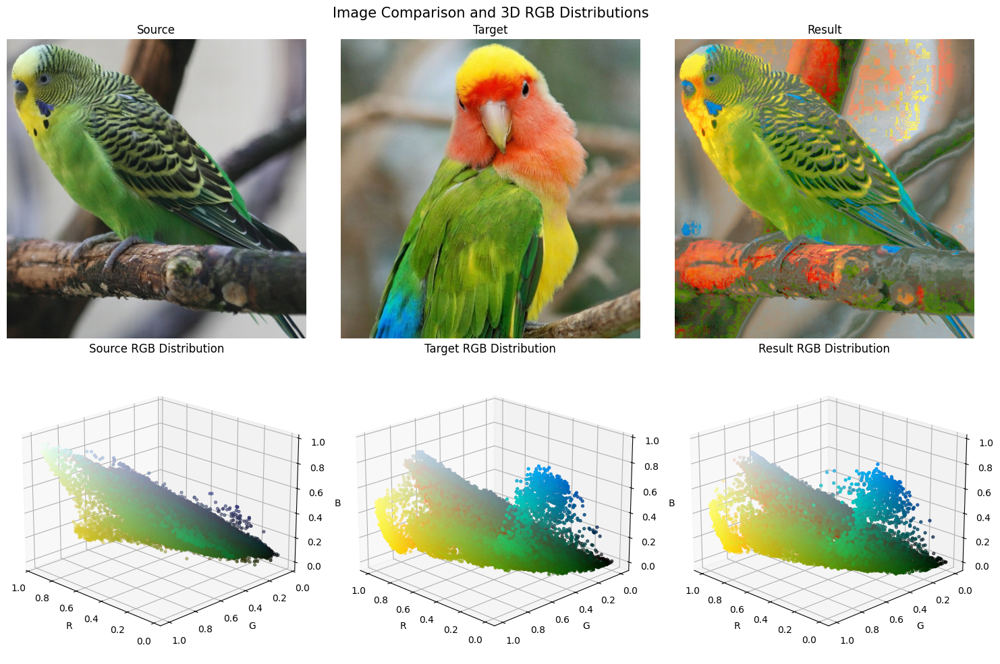

In [30]:
visualize_images_and_distributions(source, target, result)

Converged in 10 iterations


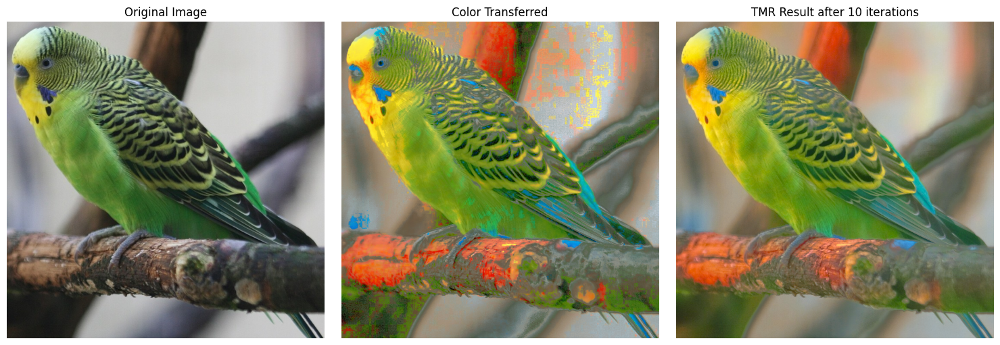

In [31]:
tmr,_,k = tmr_iterative(source, result,return_debug=True)
print(f"Converged in {k} iterations")
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(source)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(result)
plt.title("Color Transferred")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(tmr)
plt.title(f"TMR Result after {k} iterations")
plt.axis("off")

plt.tight_layout()
plt.show()

## TMR on our initial example

SWP iterations:  34%|███▍      | 86/250 [00:56<01:47,  1.53it/s]


 Converged at iteration 86 (Δ1<0.0001, Δ5<0.0005)



/tmp/ipython-input-1720154045.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


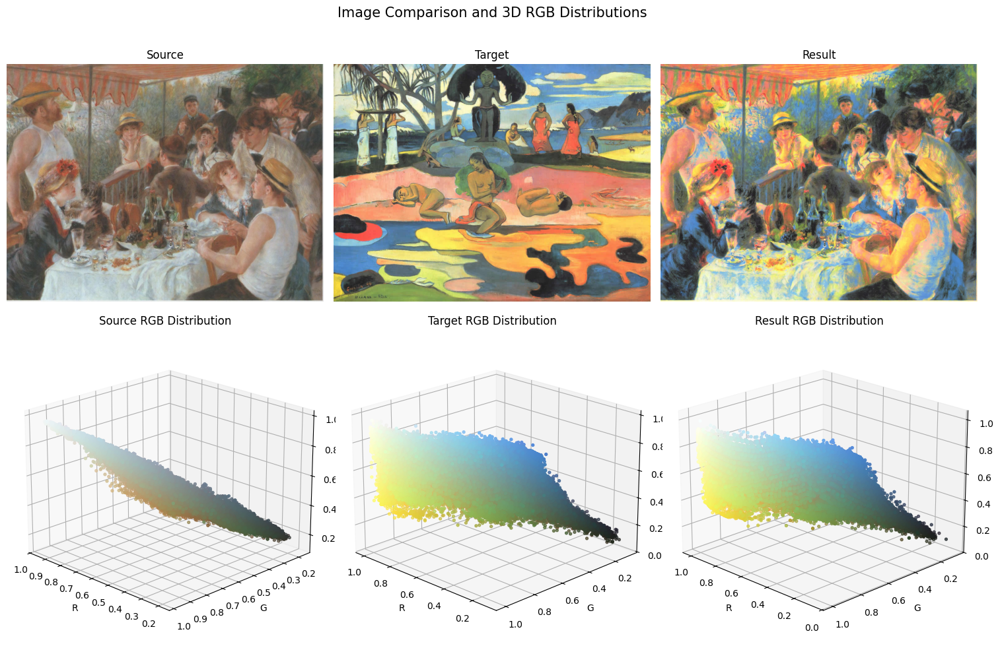

Converged in 10 iterations


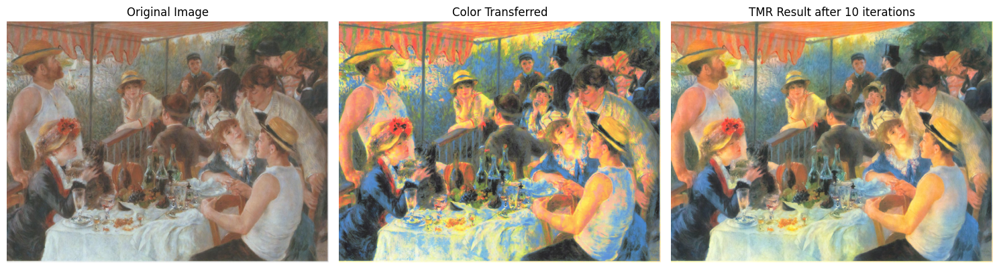

In [42]:
from skimage import io
source2 = io.imread("source.jpg")
target2 = io.imread("target.jpg")

result2, curve2 = sliced_wasserstein_projection(
    source2,
    target2,
    n_iter=250,
    n_dirs=250,
    tau=5.4,
    epsilon_short=1e-4,
    epsilon_long=5e-4,
    k_gap=5,
    patience_short=3,
    patience_long=2,
    min_iters=10,
    device='cuda'
)
visualize_images_and_distributions(source2, target2, result2)

tmr2,_,k2 = tmr_iterative(source2, result2,return_debug=True)
print(f"Converged in {k2} iterations")
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(source2)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(result2)
plt.title("Color Transferred")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(tmr2)
plt.title(f"TMR Result after {k2} iterations")
plt.axis("off")

plt.tight_layout()
plt.show()

# Applications of color transfer + Their TMR results

SWP iterations:  52%|█████▏    | 130/250 [05:28<05:02,  2.52s/it]


 Converged at iteration 130 (Δ1<0.0001, Δ5<0.0005)


Converged in 10 iterations


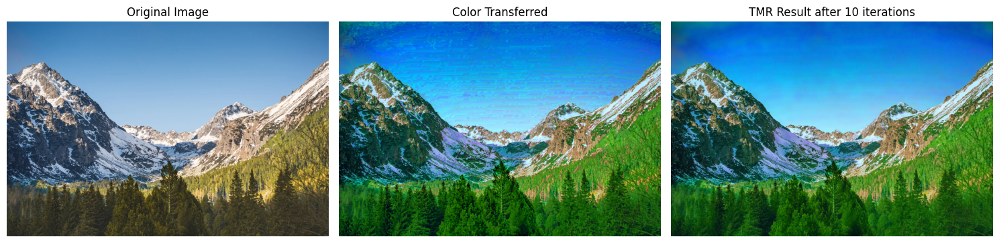

In [34]:
from skimage import io
source2 = io.imread("mountain.webp")
target2 = io.imread("fortnite.jpg")

result2, curve2 = sliced_wasserstein_projection(
    source2,
    target2,
    n_iter=250,
    n_dirs=250,
    tau=5.4,
    epsilon_short=1e-4,
    epsilon_long=5e-4,
    k_gap=5,
    patience_short=3,
    patience_long=2,
    min_iters=10,
    device='cuda'
)

tmr2,_,k2 = tmr_iterative(source2, result2,return_debug=True)
print(f"Converged in {k2} iterations")
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(source2)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(result2)
plt.title("Color Transferred")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(tmr2)
plt.title(f"TMR Result after {k2} iterations")
plt.axis("off")

plt.tight_layout()
plt.show()

/tmp/ipython-input-1720154045.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


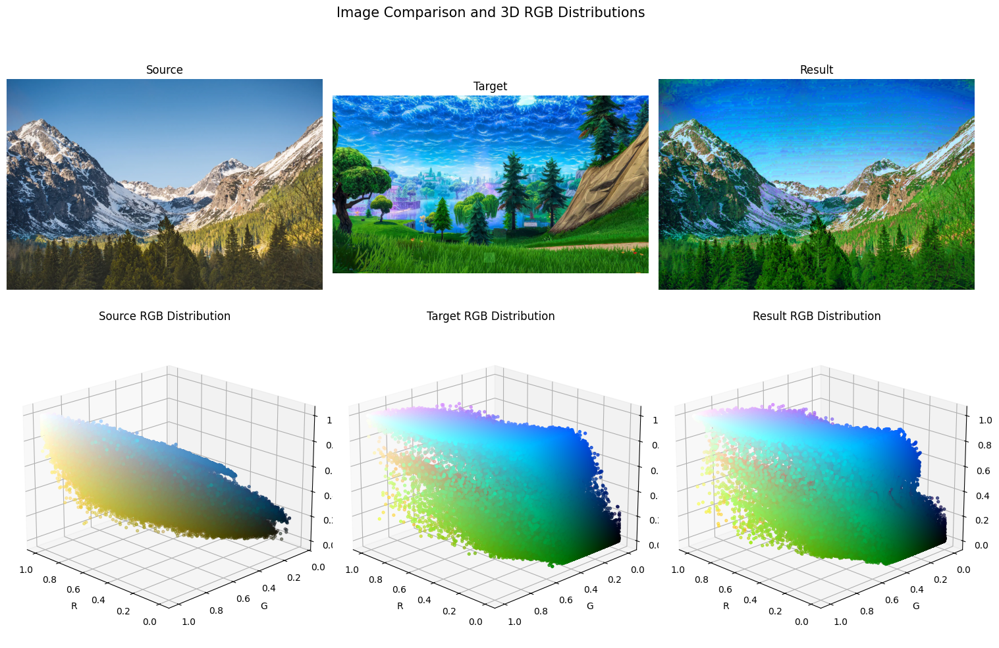

In [35]:
visualize_images_and_distributions(source2, target2, result2)

SWP iterations:  76%|███████▋  | 191/250 [12:13<03:46,  3.84s/it]


 Converged at iteration 191 (Δ1<0.0001, Δ5<0.0005)



/tmp/ipython-input-1720154045.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


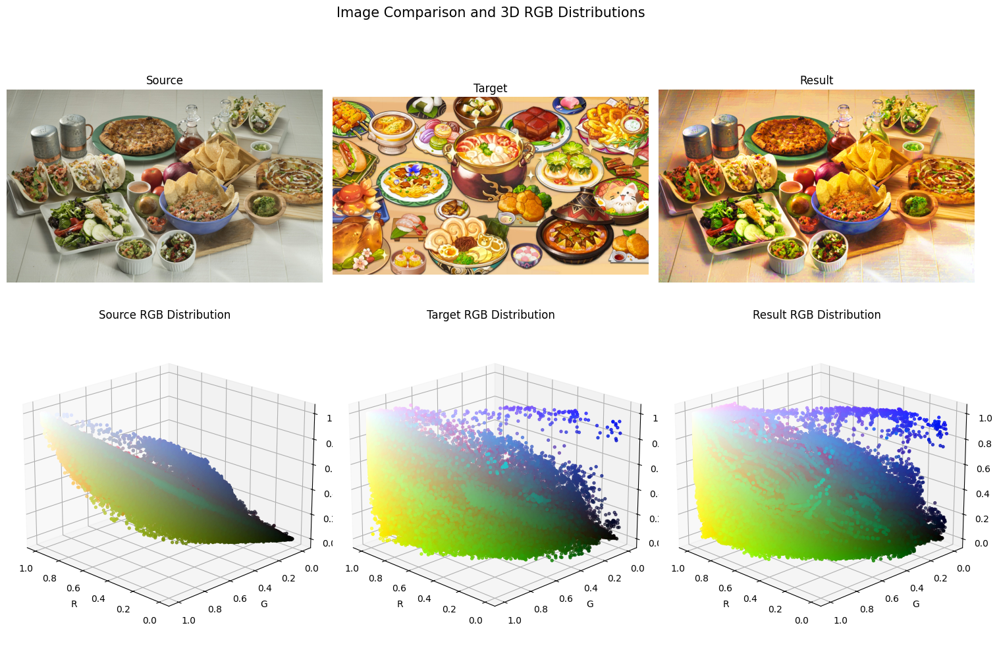

Converged in 10 iterations


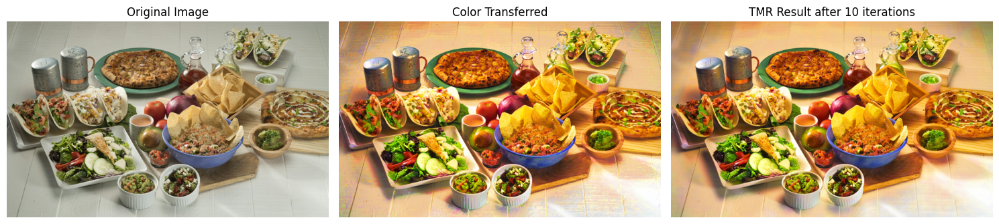

In [36]:
from skimage import io
source2 = io.imread("food2.jpg")
target2 = io.imread("anime_table2.jpeg")

result2, curve2 = sliced_wasserstein_projection(
    source2,
    target2,
    n_iter=250,
    n_dirs=250,
    tau=5.4,
    epsilon_short=1e-4,
    epsilon_long=5e-4,
    k_gap=5,
    patience_short=3,
    patience_long=2,
    min_iters=10,
    device='cuda'
)
visualize_images_and_distributions(source2, target2, result2)

tmr2,_,k2 = tmr_iterative(source2, result2,return_debug=True)
print(f"Converged in {k2} iterations")
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(source2)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(result2)
plt.title("Color Transferred")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(tmr2)
plt.title(f"TMR Result after {k2} iterations")
plt.axis("off")

plt.tight_layout()
plt.show()

SWP iterations:  44%|████▎     | 109/250 [00:48<01:02,  2.26it/s]


 Converged at iteration 109 (Δ1<0.0001, Δ5<0.0005)



/tmp/ipython-input-1720154045.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


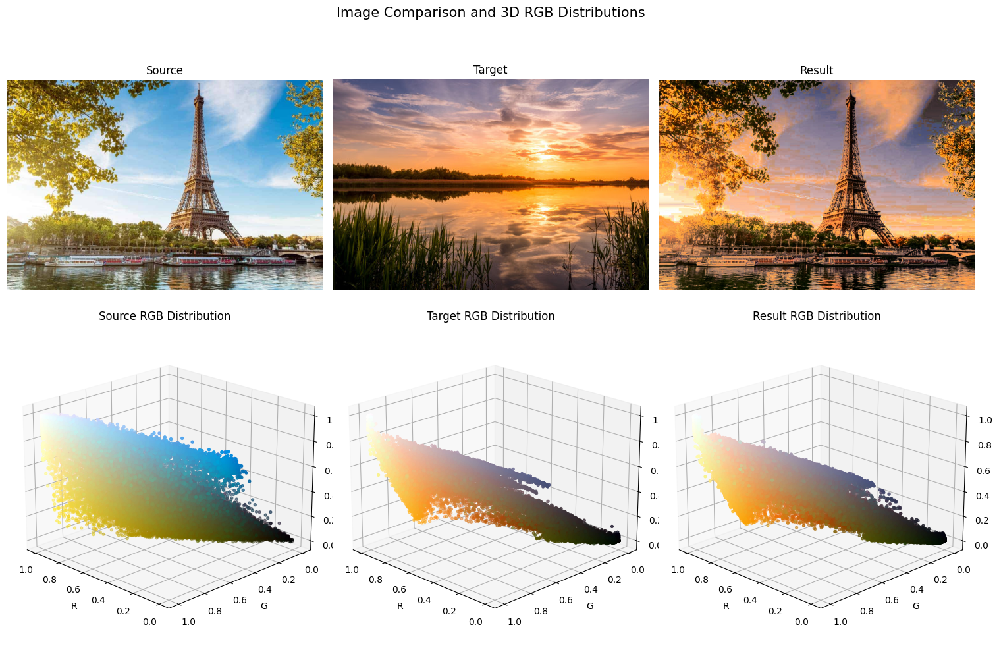

Converged in 10 iterations


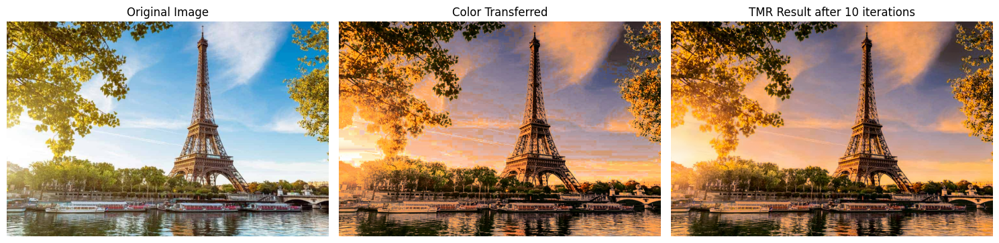

In [37]:
from skimage import io
source2 = io.imread("paris_day.jpg")
target2 = io.imread("sunset2.jpg")

result2, curve2 = sliced_wasserstein_projection(
    source2,
    target2,
    n_iter=250,
    n_dirs=250,
    tau=5.4,
    epsilon_short=1e-4,
    epsilon_long=5e-4,
    k_gap=5,
    patience_short=3,
    patience_long=2,
    min_iters=10,
    device='cuda'
)
visualize_images_and_distributions(source2, target2, result2)

tmr2,_,k2 = tmr_iterative(source2, result2,return_debug=True)
print(f"Converged in {k2} iterations")
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(source2)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(result2)
plt.title("Color Transferred")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(tmr2)
plt.title(f"TMR Result after {k2} iterations")
plt.axis("off")

plt.tight_layout()
plt.show()

# Bad Results

SWP iterations:  96%|█████████▌| 240/250 [02:08<00:05,  1.87it/s]


 Converged at iteration 240 (Δ1<0.0001, Δ5<0.0005)



/tmp/ipython-input-1720154045.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


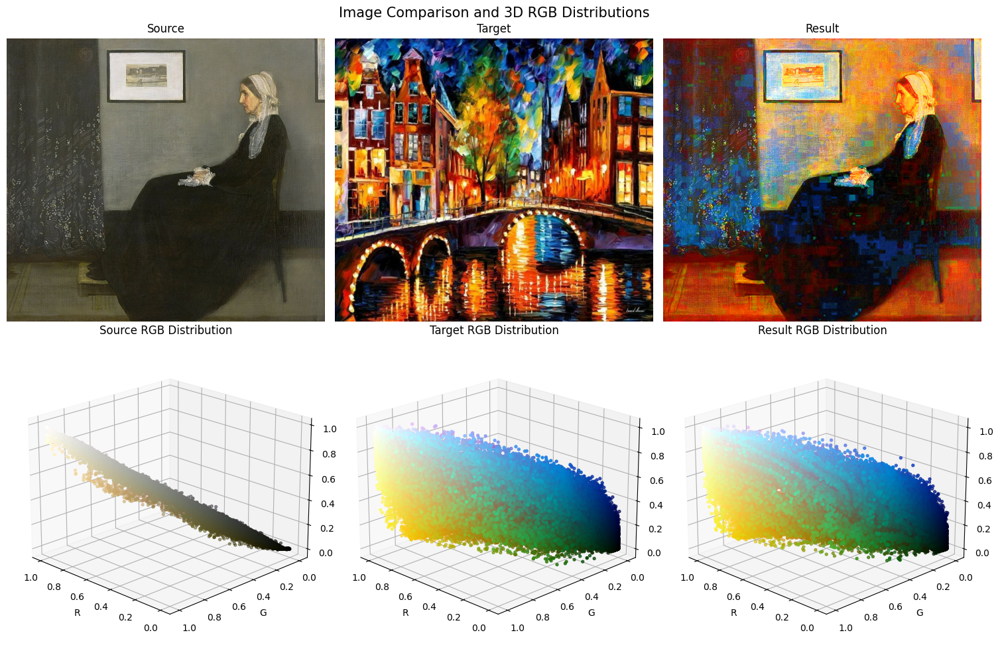

In [38]:
from skimage import io
source2 = io.imread("Monochromatic-Painting.jpg")
target2 = io.imread("colorful.jpg")

result2, curve2 = sliced_wasserstein_projection(
    source2,
    target2,
    n_iter=250,
    n_dirs=250,
    tau=5.4,
    epsilon_short=1e-4,
    epsilon_long=5e-4,
    k_gap=5,
    patience_short=3,
    patience_long=2,
    min_iters=10,
    device='cuda'
)
visualize_images_and_distributions(source2, target2, result2)

SWP iterations:  63%|██████▎   | 158/250 [01:31<00:53,  1.72it/s]


 Converged at iteration 158 (Δ1<0.0001, Δ5<0.0005)



/tmp/ipython-input-1720154045.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


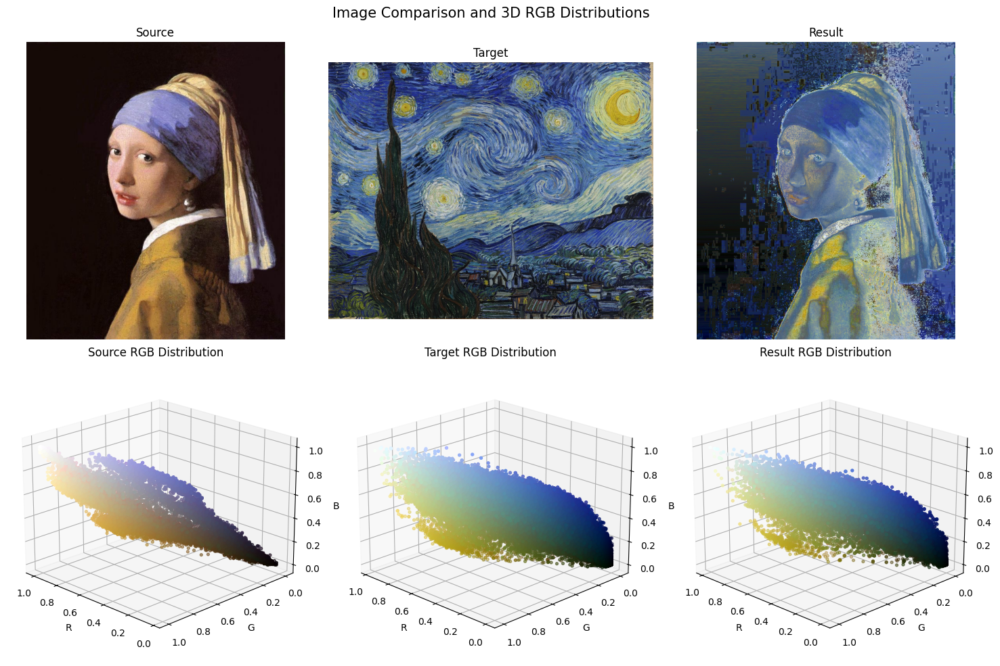

In [39]:
from skimage import io
source2 = io.imread("girl.jpg")
target2 = io.imread("starry_night.webp")

result2, curve2 = sliced_wasserstein_projection(
    source2,
    target2,
    n_iter=250,
    n_dirs=250,
    tau=5.4,
    epsilon_short=1e-4,
    epsilon_long=5e-4,
    k_gap=5,
    patience_short=3,
    patience_long=2,
    min_iters=10,
    device='cuda'
)
visualize_images_and_distributions(source2, target2, result2)

SWP iterations:  49%|████▉     | 123/250 [01:07<01:09,  1.82it/s]


 Converged at iteration 123 (Δ1<0.0001, Δ5<0.0005)



/tmp/ipython-input-1720154045.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


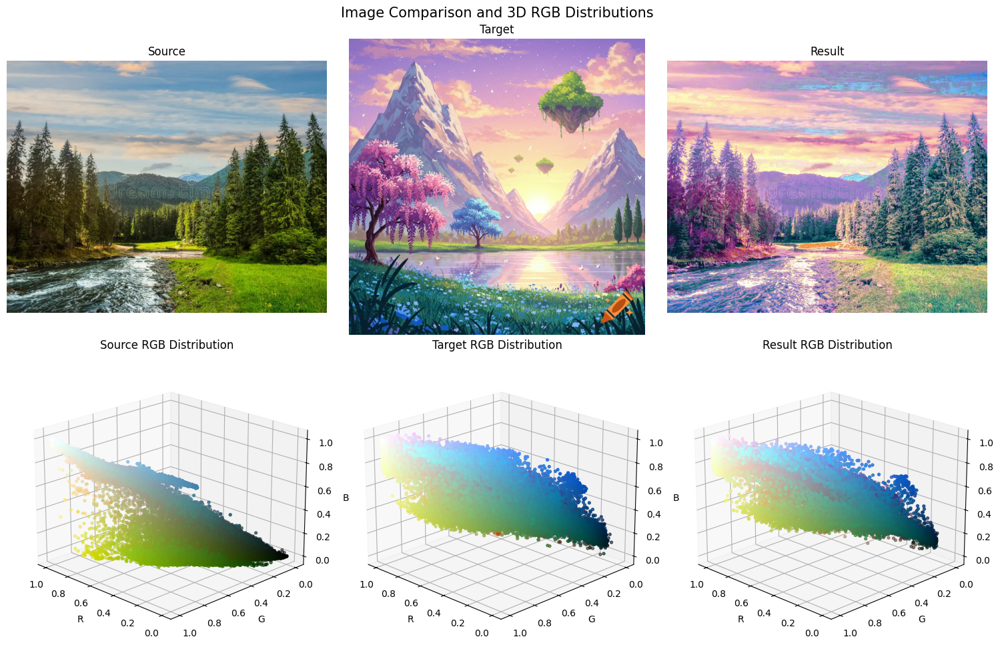

In [40]:
from skimage import io
source2 = io.imread("mountain2.webp")
target2 = io.imread("anime2.webp")

result2, curve2 = sliced_wasserstein_projection(
    source2,
    target2,
    n_iter=250,
    n_dirs=250,
    tau=5.4,
    epsilon_short=1e-4,
    epsilon_long=5e-4,
    k_gap=5,
    patience_short=3,
    patience_long=2,
    min_iters=10,
    device='cuda'
)
visualize_images_and_distributions(source2, target2, result2)